In [ ]:
# 1. Viết hàmflanger_effect(x, fs, max_delay_ms=3.0, mod_rate_hz=0.5, a=0.7) sử dụng kỹ thuật nội suy tuyến tính
import numpy as np

def flanger_effect(x, fs, max_delay_ms=3.0, mod_rate_hz=0.5, a=0.7):

    max_delay = int (max_delay_ms * 1e-3 * fs)

    N = len(x)
    y = np.zeros(N)

    for n in range(N):
        D = (max_delay / 2) * (
            1 - np.cos(
                2 * np.pi * mod_rate_hz * n / fs
            )
        )

        D_int = int(np.floor(D))
        delta = D - D_int

        if n - D_int - 1 >= 0:

            delayed = (
                (1 - delta) * x[n - D_int]
                + delta * x[n - D_int - 1]
            )

        elif n - D_int >= 0:

            delayed = x[n - D_int]

        else:

            delayed = 0

        y[n] = x[n] + a * delayed

    return y

In [ ]:
#2. Áp dụng lên file nhạc guitar clean hoặc distorted guitar
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read
from IPython.display import Audio, display

fs, x = read("guitar1.wav")

x = x.astype(float)
if x.ndim == 2:
    x = np.mean(x, axis=1)
x = x / np.max(np.abs(x))


y_flanger = flanger_effect(
    x,
    fs,
    max_delay_ms=3.0,
    mod_rate_hz=0.5,
    a=0.7
)



y_flanger = y_flanger / np.max(np.abs(y_flanger))


print("Tín hiệu guitar gốc:")
display(Audio(x, rate=fs))

print("Tín hiệu guitar sau Flanger:")
display(Audio(y_flanger, rate=fs))

Tín hiệu guitar gốc:


Tín hiệu guitar sau Flanger:


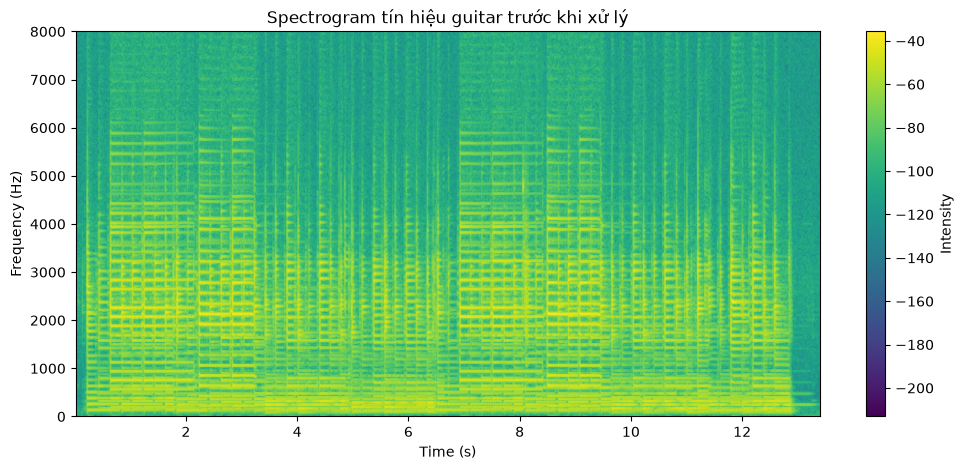

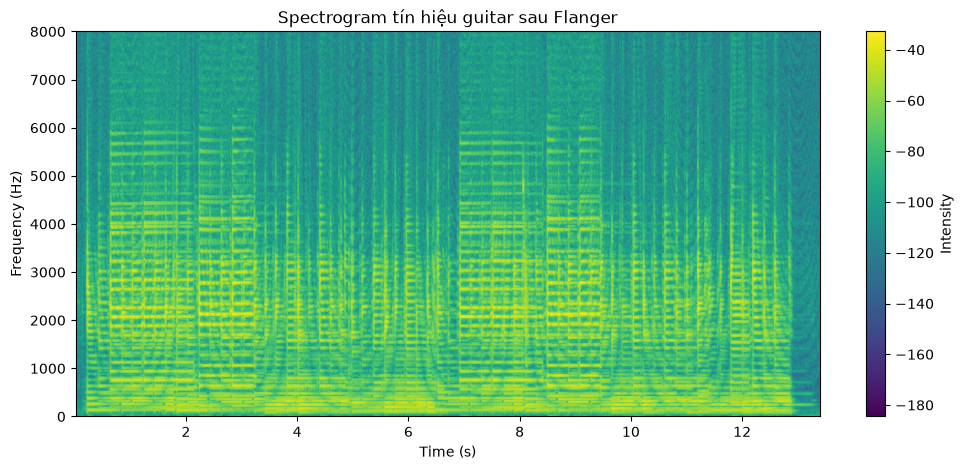

In [3]:
# 3. Vẽ phổ Spectrogram của tín hiệu trước và sau khi xử lý.
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.specgram(
    x,
    Fs=fs,
    NFFT=2048,
    noverlap=1536
)

plt.ylim(0, 8000)

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram tín hiệu guitar trước khi xử lý")

plt.colorbar(label="Intensity")
plt.show()



plt.figure(figsize=(12, 5))

plt.specgram(
    y_flanger,
    Fs=fs,
    NFFT=2048,
    noverlap=1536
)

plt.ylim(0, 8000)

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram tín hiệu guitar sau Flanger")

plt.colorbar(label="Intensity")
plt.show()